<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week08_1026/car_classification_1026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Car Evaluation 분류 (unacc / acc / good / vgood)
- 데이터: UCI Car Evaluation (`car.data`) — 1,728행, 입력 6개(전부 범주형 문자), 정답 `output` 4클래스
- 교수님 `ML_classification_Car.ipynb` 흐름(LabelEncoder → StandardScaler → 여러 분류 모델 비교)을 따름
- **불균형 데이터**: unacc 70%, acc 22%, good 4%, vgood 4% → accuracy만 보면 안 되고 **macro F1**도 같이 봄

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. 데이터 읽기
내 드라이브 `Colab Notebooks` 폴더의 `car.data`를 읽음.
`car.data`에는 열 이름(헤더)이 없으므로 `header=None`.

In [16]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data", header=None)
df.columns = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
print(df.shape)
df.head()

(1728, 7)


,price,maint,doors,persons,lug_capacity,safety,output
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [17]:
df.isnull().sum()

,0
price,0
maint,0
doors,0
persons,0
lug_capacity,0
safety,0
output,0


In [18]:
df['output'].value_counts()

,count
output,
unacc,1210
acc,384
good,69
vgood,65


## 2. 인코딩 — LabelEncoder (교수님 원본 방식)
모든 열이 문자라서 숫자로 바꿔야 모델에 넣을 수 있음.
`LabelEncoder`는 **알파벳 순서**로 번호를 매김 → 아래 출력처럼 `price`가 high=0, low=1, med=2, vhigh=3이 되어 **원래 크기 순서(low<med<high<vhigh)가 깨짐**. (7번에서 순서를 지킨 인코딩과 비교)

In [19]:
raw_df = df.copy()   # 7번 비교 실험용 원본 보관

columns = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
label_encoders = {}
for column in columns:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])

for column in columns:
    le = label_encoders[column]
    print(column, {c: int(i) for c, i in zip(le.classes_, le.transform(le.classes_))})

price {'high': 0, 'low': 1, 'med': 2, 'vhigh': 3}
maint {'high': 0, 'low': 1, 'med': 2, 'vhigh': 3}
doors {'2': 0, '3': 1, '4': 2, '5more': 3}
persons {'2': 0, '4': 1, 'more': 2}
lug_capacity {'big': 0, 'med': 1, 'small': 2}
safety {'high': 0, 'low': 1, 'med': 2}
output {'acc': 0, 'good': 1, 'unacc': 2, 'vgood': 3}


In [20]:
df.head()

,price,maint,doors,persons,lug_capacity,safety,output
0,3,3,0,0,2,1,2
1,3,3,0,0,2,2,2
2,3,3,0,0,2,0,2
3,3,3,0,0,1,1,2
4,3,3,0,0,1,2,2


## 3. 입력/정답 분리 → 학습/시험 분리 → 표준화
교수님 원본과 다른 점 두 가지:
- `stratify=y`: good·vgood가 각각 4%뿐이라, 무작위로 나누면 시험 데이터에 거의 안 들어갈 수 있음 → 클래스 비율 유지
- **분리 먼저, 표준화는 나중**: 원본은 전체 X로 `fit_transform` 후 분리해서 시험 데이터 정보가 평균·표준편차에 섞임(데이터 누수). 학습 데이터로만 `fit`하고 시험 데이터는 `transform`만 함

In [21]:
X = df.drop('output', axis=1).values
y = df['output'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1382, 6), (346, 6), (1382,), (346,))

## 4. 여러 분류 모델 비교

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "Random Forest": RandomForestClassifier(random_state=0),
    "KNN": KNeighborsClassifier(),
    "MLP": MLPClassifier(max_iter=1000, random_state=0),
}

results = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average='macro')
    results.append([name, acc, f1])

    print(f"\n--- {name} ---")
    print("Accuracy:", round(acc, 4), " Macro F1:", round(f1, 4))
    print(confusion_matrix(y_test, pred))

result_df = pd.DataFrame(results, columns=['model', 'accuracy', 'macro_f1'])
result_df = result_df.sort_values('macro_f1', ascending=False).reset_index(drop=True)
result_df


--- Logistic Regression ---
Accuracy: 0.6908  Macro F1: 0.3138
[[ 11   0  64   2]
 [  3   0  11   0]
 [ 16   0 226   0]
 [  4   0   7   2]]

--- SVM ---
Accuracy: 0.8757  Macro F1: 0.6633
[[ 65   0  12   0]
 [ 14   0   0   0]
 [ 16   0 226   0]
 [  1   0   0  12]]

--- Decision Tree ---
Accuracy: 0.9566  Macro F1: 0.9414
[[ 69   1   6   1]
 [  0  14   0   0]
 [  6   0 236   0]
 [  1   0   0  12]]

--- Random Forest ---
Accuracy: 0.9624  Macro F1: 0.9446
[[ 74   0   3   0]
 [  3  11   0   0]
 [  7   0 235   0]
 [  0   0   0  13]]

--- KNN ---
Accuracy: 0.922  Macro F1: 0.7912
[[ 68   0   9   0]
 [ 10   4   0   0]
 [  6   0 236   0]
 [  2   0   0  11]]

--- MLP ---
Accuracy: 0.9827  Macro F1: 0.9777
[[ 74   0   3   0]
 [  0  14   0   0]
 [  2   0 240   0]
 [  1   0   0  12]]


,model,accuracy,macro_f1
0,MLP,0.982659,0.977682
1,Random Forest,0.962428,0.944605
2,Decision Tree,0.956647,0.941440
3,KNN,0.921965,0.791167
4,SVM,0.875723,0.663278
5,Logistic Regression,0.690751,0.313828


## 5. 가장 좋은 모델의 분류 리포트와 혼동행렬
macro F1 기준 1등 모델. 숫자 0~3이 어떤 클래스인지는 `label_encoders['output'].classes_` 순서(acc, good, unacc, vgood).

Best: MLP
              precision    recall  f1-score   support

         acc       0.96      0.96      0.96        77
        good       1.00      1.00      1.00        14
       unacc       0.99      0.99      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.99      0.97      0.98       346
weighted avg       0.98      0.98      0.98       346



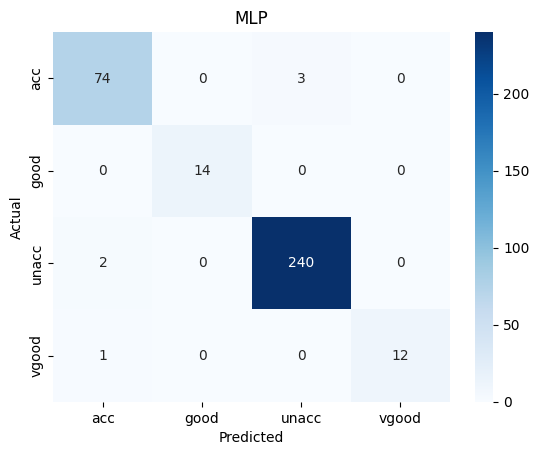

In [23]:
best_name = result_df.loc[0, 'model']
best_pred = models[best_name].predict(X_test)
class_names = label_encoders['output'].classes_

print("Best:", best_name)
print(classification_report(y_test, best_pred, target_names=class_names))

cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(best_name)
plt.show()

## 6. 기준선 — 전부 unacc라고 찍으면?
불균형 데이터에서 accuracy의 단점을 확인. 아무것도 배우지 않아도 accuracy가 약 70%.

In [24]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 4))
print("Macro F1:", round(f1_score(y_test, dummy_pred, average='macro'), 4))

Accuracy: 0.6994
Macro F1: 0.2058


## 7. 추가 실험 — 순서를 지킨 인코딩(OrdinalEncoder)
입력 6개는 모두 **순서가 있는 범주**(low<med<high<vhigh 등)이므로 순서대로 번호를 매기면 결과가 어떻게 달라지는지 비교. 같은 분할(random_state=0, stratify)을 사용.

In [25]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.base import clone

order = [
    ['low', 'med', 'high', 'vhigh'],   # price
    ['low', 'med', 'high', 'vhigh'],   # maint
    ['2', '3', '4', '5more'],          # doors
    ['2', '4', 'more'],                # persons
    ['small', 'med', 'big'],           # lug_capacity
    ['low', 'med', 'high'],            # safety
]
X_ord = OrdinalEncoder(categories=order).fit_transform(raw_df.drop('output', axis=1).astype(str))

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_ord, y, test_size=0.2, random_state=0, stratify=y)
sc = StandardScaler()
Xo_train = sc.fit_transform(Xo_train)
Xo_test = sc.transform(Xo_test)

compare = []
for name, clf in models.items():
    clf = clone(clf)
    clf.fit(Xo_train, yo_train)
    pred = clf.predict(Xo_test)
    compare.append([name, f1_score(yo_test, pred, average='macro')])

compare_df = pd.DataFrame(compare, columns=['model', 'macro_f1_ordinal'])
result_df.merge(compare_df, on='model')[['model', 'macro_f1', 'macro_f1_ordinal']]

,model,macro_f1,macro_f1_ordinal
0,MLP,0.977682,0.960761
1,Random Forest,0.944605,0.964890
2,Decision Tree,0.941440,0.959488
3,KNN,0.791167,0.856554
4,SVM,0.663278,0.912061
5,Logistic Regression,0.313828,0.643370
